In [1]:
#pip install pandas

In [2]:
#pip install matplotlib

In [3]:
#pip install numpy

In [4]:
#pip install seaborn

In [5]:
#pip install scikit-learn

In [6]:
#pip install imbalanced-learn

In [7]:
#pip install feature-engine

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.naive_bayes import GaussianNB, BernoulliNB, MultinomialNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import classification_report,ConfusionMatrixDisplay,accuracy_score
import pickle

import warnings
warnings.filterwarnings('ignore')

In [10]:
df=pd.read_csv("healthcare-dataset-stroke-data.csv")
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [11]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

In [12]:
df.tail()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [14]:
df.shape

(5110, 12)

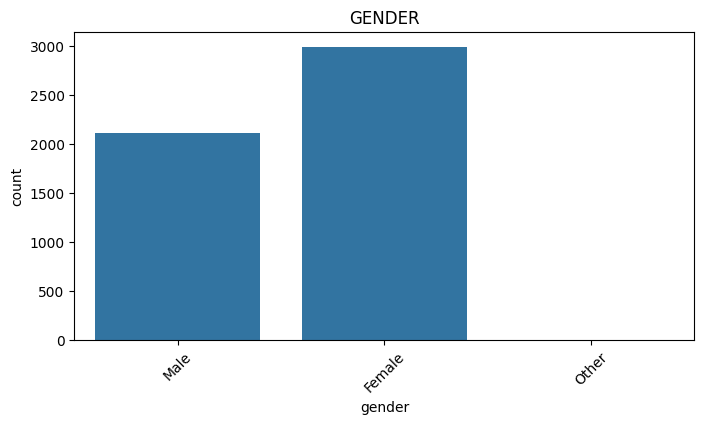

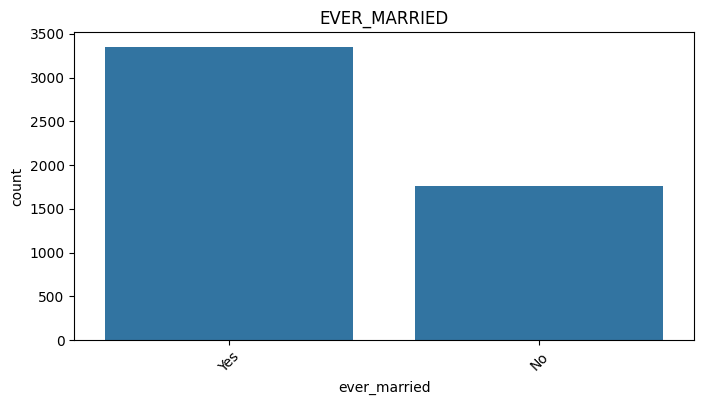

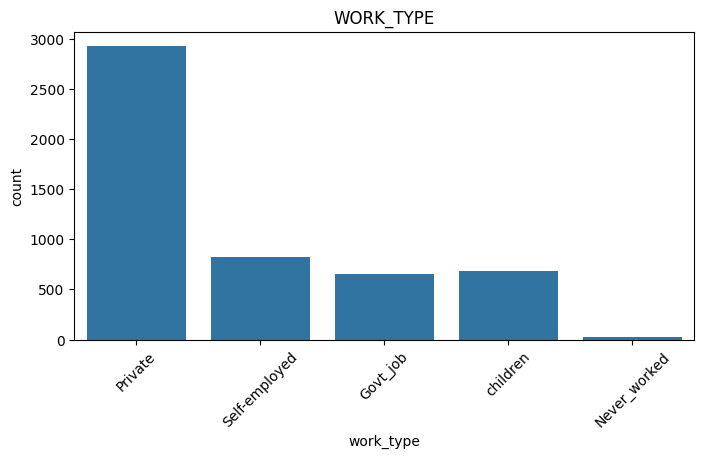

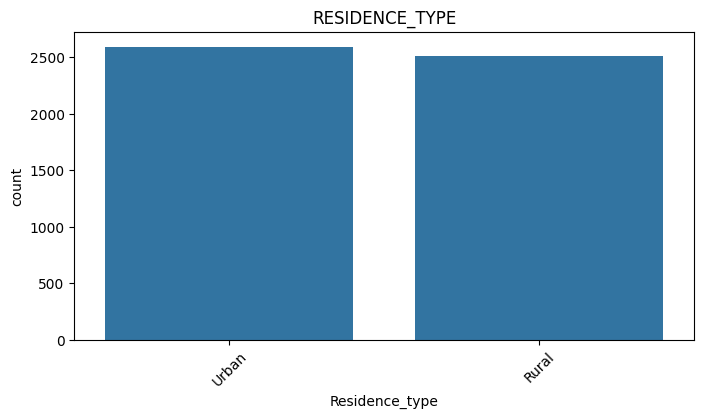

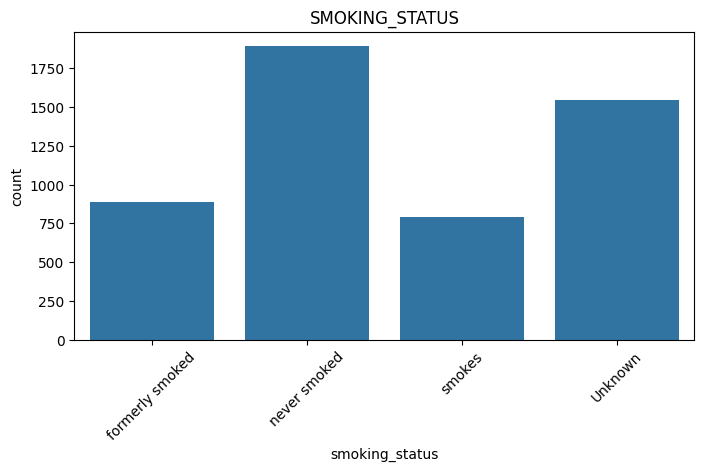

In [19]:
# BARCHART for categorical columns
selected_columns = [
    'gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status'
]

# Loop through every categorical column in the DataFrame
for col in df[selected_columns]:
    plt.figure(figsize=(8, 4)) # Adjust the figure size as needed
    sns.countplot(x=col, data=df)
    plt.title(col.upper()) # Set the title to the column name in uppercase
    plt.xticks(rotation=45) # Rotate labels if they overlap
    plt.show()

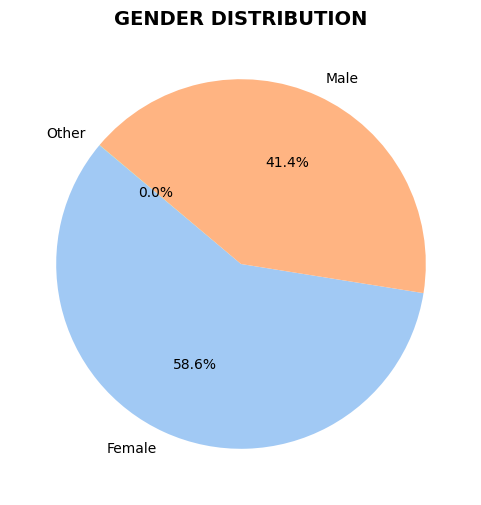

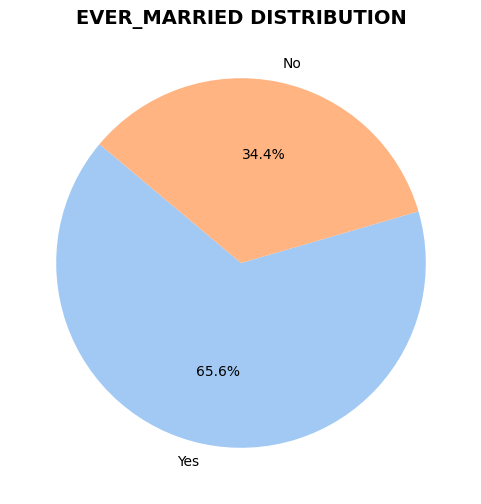

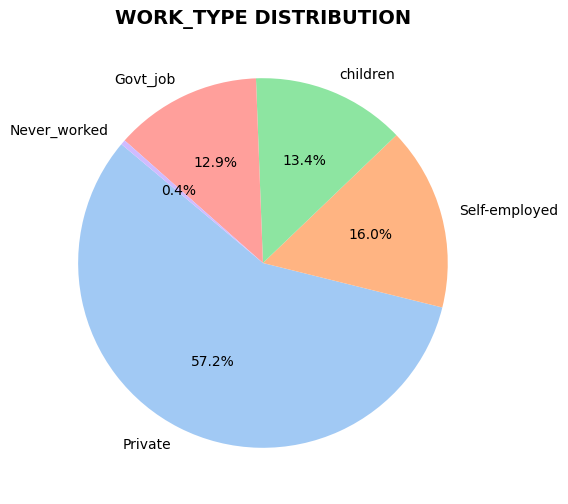

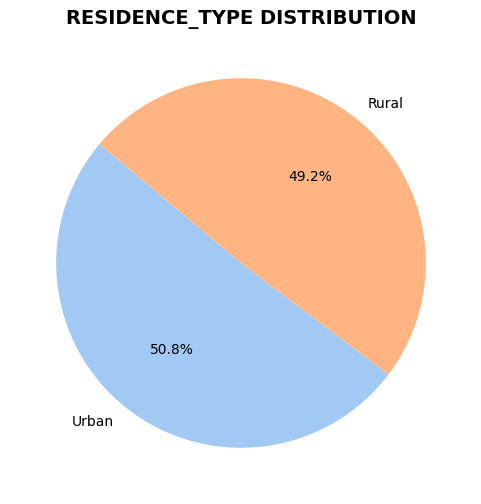

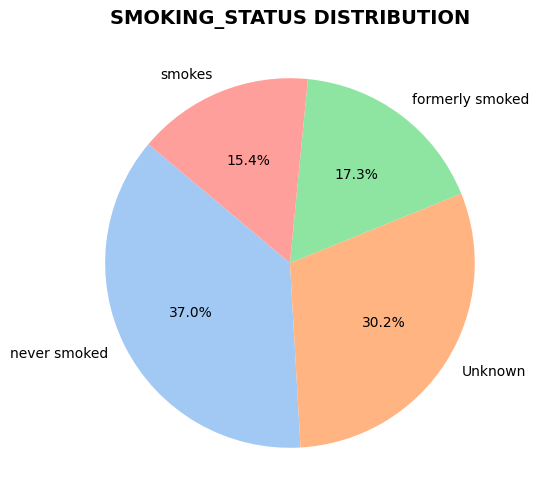

In [20]:
# PIE CHART
# Filter for only categorical columns ('object' or 'category' types)
categorical_cols = df.select_dtypes(include=['object', 'category'])

# Loop through each categorical column and create a pie chart
for col in categorical_cols:
    data_counts = df[col].value_counts()

    # Set up the plot
    plt.figure(figsize=(6, 6))

    # Create the pie chart
    plt.pie(
        data_counts,
        labels=data_counts.index, # Category labels
        autopct='%1.1f%%',  # Show percentage on the chart
        startangle=140,  # Rotate the start of the pie chart
        colors=sns.color_palette('pastel')  # Uses seaborn's pastel color palette
    )
    plt.title(f'{col.upper()} DISTRIBUTION', fontsize=14, weight='bold')
    plt.show()

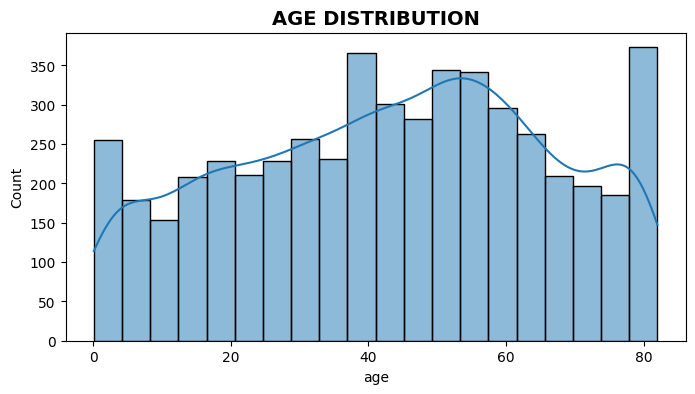

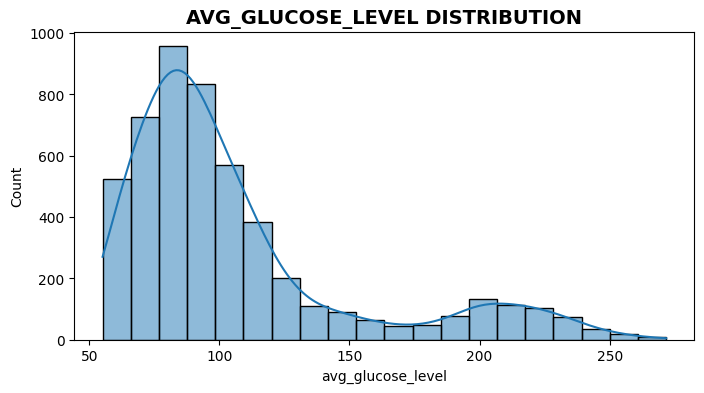

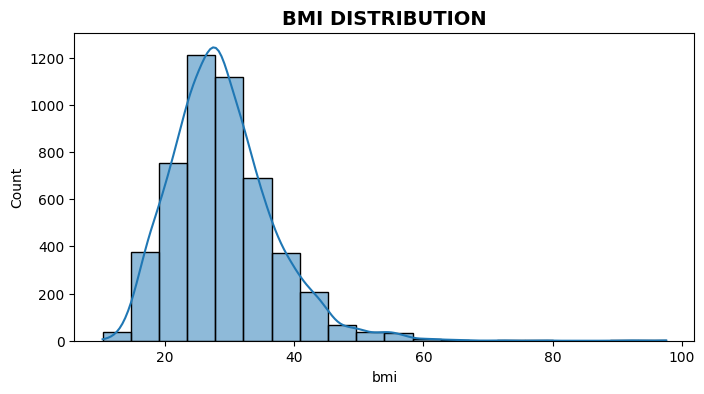

In [22]:
#HISTOGRAM 
#selected columns for histogram visualization
numerical_cols = ['age','avg_glucose_level','bmi']

# Loop through every numerical column in the DataFrame
for column in df[numerical_cols]:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[column], bins=20, kde=True) # Adjust the number of bins as needed
    plt.title(f'{column.upper()} DISTRIBUTION', fontsize=14, weight='bold')
    plt.show()

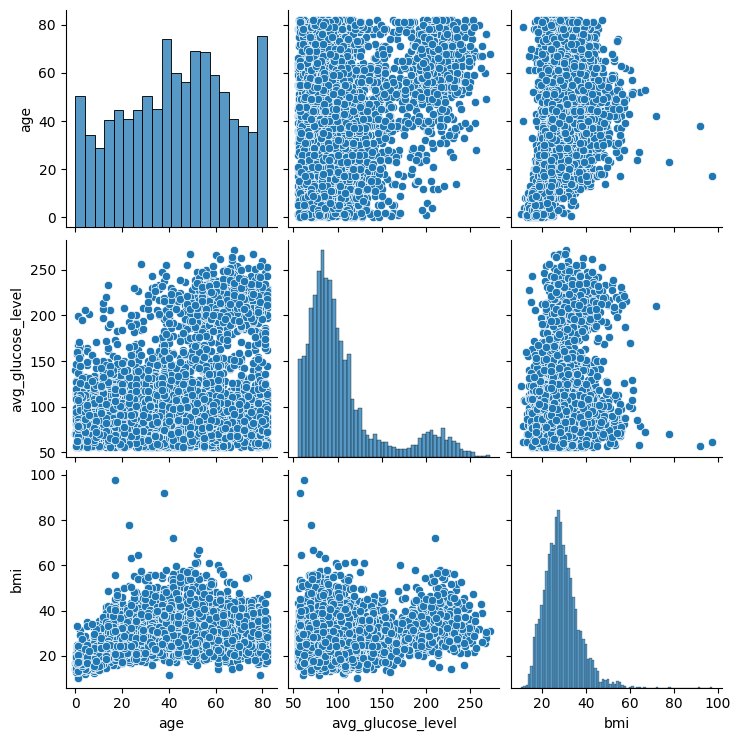

In [ ]:

#PAIR PLOT
numerical_cols = ['age','avg_glucose_level','bmi']
sns.pairplot(df[numerical_cols])
plt.show()

In [ ]:
df.dtypes

id                     int64
gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object

In [ ]:
df['gender'].unique()

array(['Male', 'Female', 'Other'], dtype=object)

In [ ]:
le=LabelEncoder()

In [ ]:
df['gender']=le.fit_transform(df['gender'])

In [ ]:
df['gender'].unique()

array([1, 0, 2])

In [ ]:
le1=LabelEncoder()

In [ ]:
df['ever_married']=le1.fit_transform(df['ever_married'])

In [ ]:
df['ever_married'].unique()

array([1, 0])

In [ ]:
le2=LabelEncoder()

In [ ]:
df['work_type']=le2.fit_transform(df['work_type'])

In [ ]:
le3=LabelEncoder()

In [ ]:
df['Residence_type']=le3.fit_transform(df['Residence_type'])

In [16]:
le4=LabelEncoder()

In [ ]:
df['smoking_status']=le4.fit_transform(df['smoking_status'])

In [ ]:
df.describe()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000,5110.000000
mean,36517.829354,0.414286,43.226614,0.097456,0.054012,0.656164,2.167710,0.508023,106.147677,28.893237,1.376908,0.048728
std,21161.721625,0.493044,22.612647,0.296607,0.226063,0.475034,1.090293,0.499985,45.283560,7.854067,1.071534,0.215320
min,67.000000,0.000000,0.080000,0.000000,0.000000,0.000000,0.000000,0.000000,55.120000,10.300000,0.000000,0.000000
25%,17741.250000,0.000000,25.000000,0.000000,0.000000,0.000000,2.000000,0.000000,77.245000,23.500000,0.000000,0.000000
50%,36932.000000,0.000000,45.000000,0.000000,0.000000,1.000000,2.000000,1.000000,91.885000,28.100000,2.000000,0.000000
75%,54682.000000,1.000000,61.000000,0.000000,0.000000,1.000000,3.000000,1.000000,114.090000,33.100000,2.000000,0.000000
max,72940.000000,2.000000,82.000000,1.000000,1.000000,1.000000,4.000000,1.000000,271.740000,97.600000,3.000000,1.000000


In [ ]:
df=df.drop_duplicates()

In [ ]:
df.isna().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

In [ ]:
df=df.fillna(df.mean(numeric_only=True))

In [ ]:
df.isna().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

In [ ]:
df=df.drop('id', axis=1)

In [ ]:
df.dtypes

gender                 int64
age                  float64
hypertension           int64
heart_disease          int64
ever_married           int64
work_type              int64
Residence_type         int64
avg_glucose_level    float64
bmi                  float64
smoking_status         int64
stroke                 int64
dtype: object

In [ ]:
df.isna().sum()

gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

<Axes: >

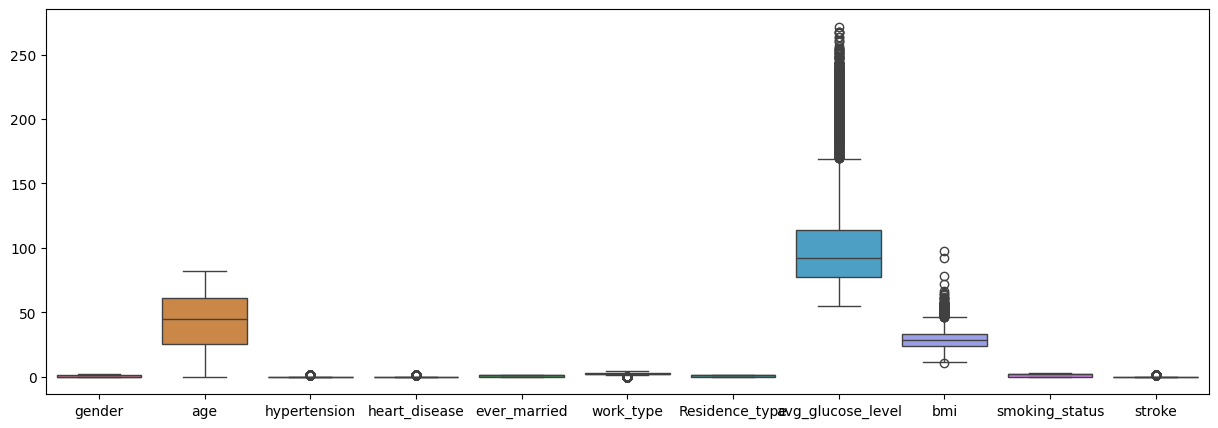

In [ ]:
plt.figure(figsize=(15, 5))
sns.boxplot(df)

In [ ]:
df["stroke"].value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

In [ ]:
x=df.drop('stroke', axis=1)
y=df['stroke']

<Axes: >

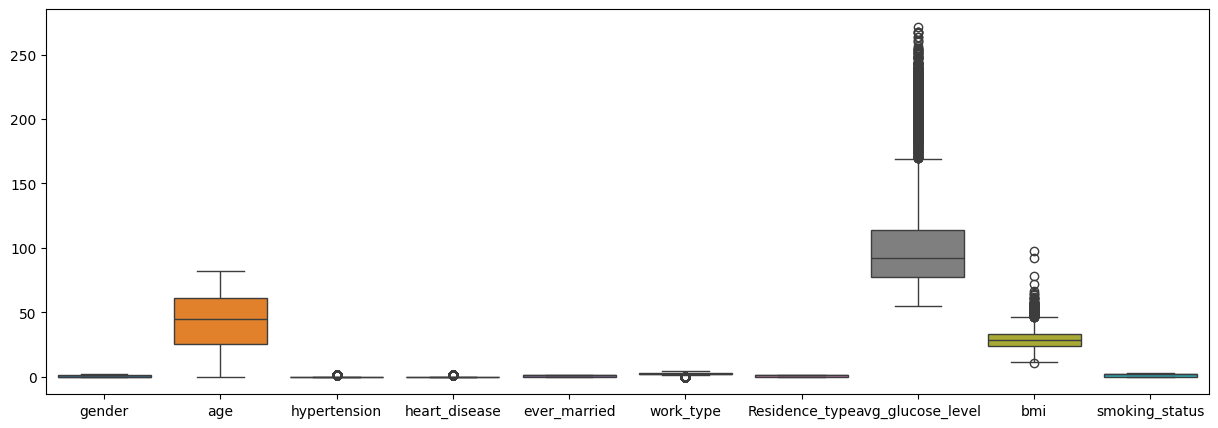

In [ ]:
plt.figure(figsize=(15, 5))
sns.boxplot(x)

In [ ]:
over=SMOTE(random_state=1)
x,y=over.fit_resample(x,y)

In [ ]:
x

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,1,67.000000,0,1,1,2,1,228.690000,36.600000,1
1,0,61.000000,0,0,1,3,0,202.210000,28.893237,2
2,1,80.000000,0,1,1,2,0,105.920000,32.500000,2
3,0,49.000000,0,0,1,2,1,171.230000,34.400000,3
4,0,79.000000,1,0,1,3,0,174.120000,24.000000,2
...,...,...,...,...,...,...,...,...,...,...
9717,0,38.117138,0,0,1,2,0,101.017762,28.976026,1
9718,0,77.910399,0,0,1,3,0,60.676944,28.893237,1
9719,1,60.296859,0,0,1,2,0,111.539291,28.952381,2
9720,0,76.097023,0,0,1,2,1,125.444735,30.858214,2


<Axes: >

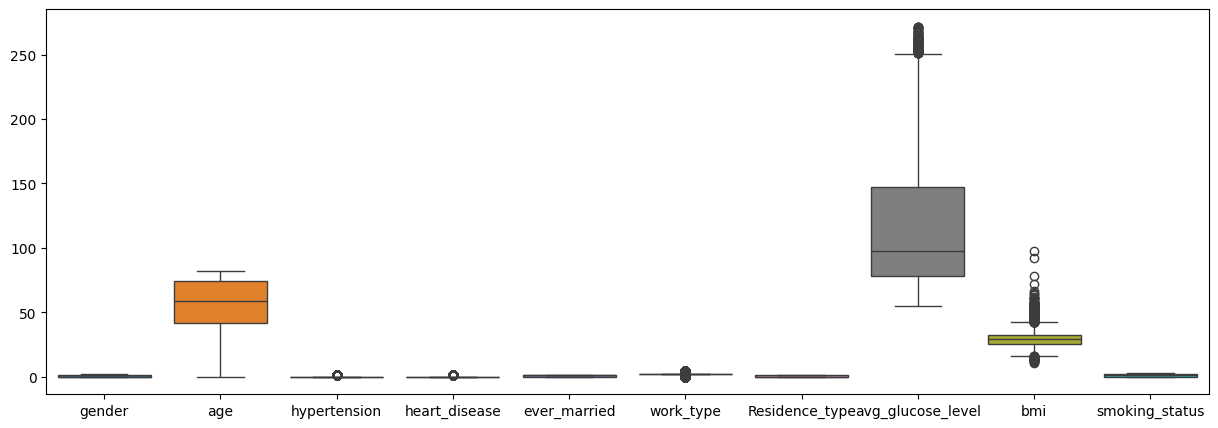

In [ ]:
plt.figure(figsize=(15, 5))
sns.boxplot(x)

In [ ]:
q1=x.avg_glucose_level.quantile(.25)
q3=x.avg_glucose_level.quantile(.75)
iqr=q3-q1
#print(q1,q3,iqr)
LB=q1-(1.5*iqr)
UB=q3+(1.5*iqr)

x['avg_glucose_level']=pd.DataFrame(np.where(x.avg_glucose_level>UB,UB,np.where(x.avg_glucose_level<LB,LB,x.avg_glucose_level)))

In [ ]:
q1=x.bmi.quantile(.25)
q3=x.bmi.quantile(.75)
iqr=q3-q1
#print(q1,q3,iqr)
LB=q1-(1.5*iqr)
UB=q3+(1.5*iqr)

x['bmi']=pd.DataFrame(np.where(x.bmi>UB,UB,np.where(x.bmi<LB,LB,x.bmi)))

In [ ]:
#from feature_engine.outliers import winsorizer
#winsor=winsorizer(capping_method='iqr', tail='both', fold=1.5)

In [ ]:
# Q1=x.quantile(0.25)
# Q3=x.quantile(0.75)
# IQR=Q3-Q1

# lower_bound=Q1-1.5*IQR
# upper_bound=Q3-1.5*IQR

# x=x.clip(lower=lower_bound, upper=upper_bound, axis=1)

<Axes: >

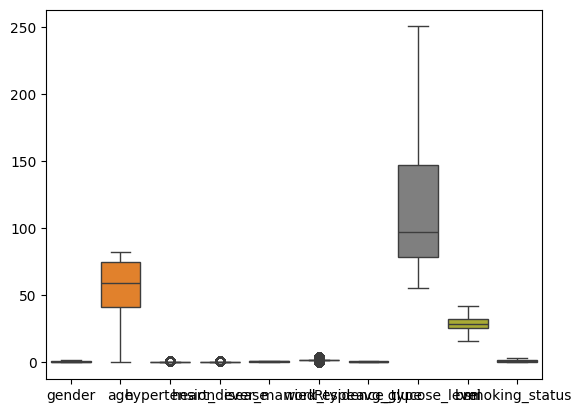

In [ ]:
plt.Figure(figsize=(15,5))
sns.boxplot(x)

In [ ]:
y.value_counts()

stroke
1    4861
0    4861
Name: count, dtype: int64

In [ ]:
over=SMOTE(random_state=1)
x,y=over.fit_resample(x,y)

In [ ]:
y.value_counts()

stroke
1    4861
0    4861
Name: count, dtype: int64

<Axes: >

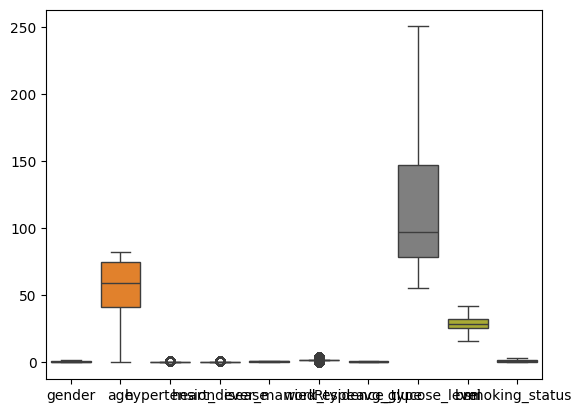

In [ ]:
plt.Figure(figsize=(15,5))
sns.boxplot(x)

In [ ]:
q=MinMaxScaler()
x=q.fit_transform(x)
x

array([[0.5       , 0.81689453, 0.        , ..., 0.88699365, 0.78429662,
        0.33333333],
       [0.        , 0.74365234, 0.        , ..., 0.75167307, 0.49490652,
        0.66666667],
       [0.5       , 0.97558594, 0.        , ..., 0.25960291, 0.63034101,
        0.66666667],
       ...,
       [0.5       , 0.73506908, 0.        , ..., 0.28831914, 0.4971274 ,
        0.66666667],
       [0.        , 0.92794217, 0.        , ..., 0.35938004, 0.56869169,
        0.66666667],
       [0.        , 0.97338516, 0.        , ..., 0.94319644, 0.44175522,
        0.66666667]], shape=(9722, 10))

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=1)

In [ ]:
x_test.shape, x_train.shape

((1945, 10), (7777, 10))

In [ ]:
y_test.shape, y_train.shape

((1945,), (7777,))

In [ ]:
k=KNeighborsClassifier()
r=RandomForestClassifier()
d=DecisionTreeClassifier()
a=AdaBoostClassifier()
l=LogisticRegression()
s=SVC()
g=GradientBoostingClassifier()
n=GaussianNB()
b=BernoulliNB()
m=MultinomialNB()

                  KNeighborsClassifier()
..................................................
accuracy =  87.91773778920309
              precision    recall  f1-score   support

           0       0.94      0.81      0.87       964
           1       0.83      0.95      0.89       981

    accuracy                           0.88      1945
   macro avg       0.89      0.88      0.88      1945
weighted avg       0.89      0.88      0.88      1945



                  RandomForestClassifier()
..................................................
accuracy =  94.65295629820052
              precision    recall  f1-score   support

           0       0.97      0.92      0.94       964
           1       0.93      0.97      0.95       981

    accuracy                           0.95      1945
   macro avg       0.95      0.95      0.95      1945
weighted avg       0.95      0.95      0.95      1945



                  DecisionTreeClassifier()
..................................................
ac

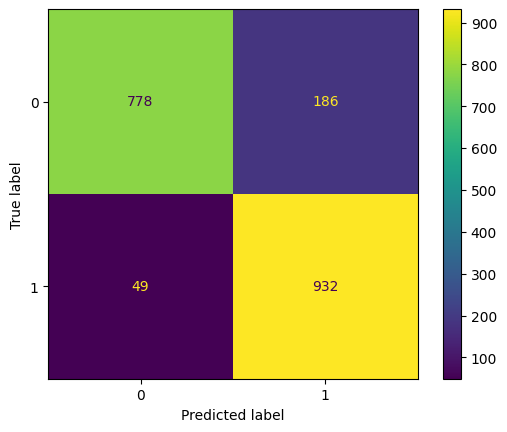

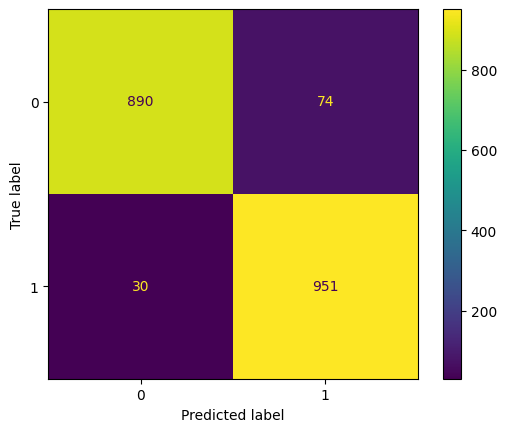

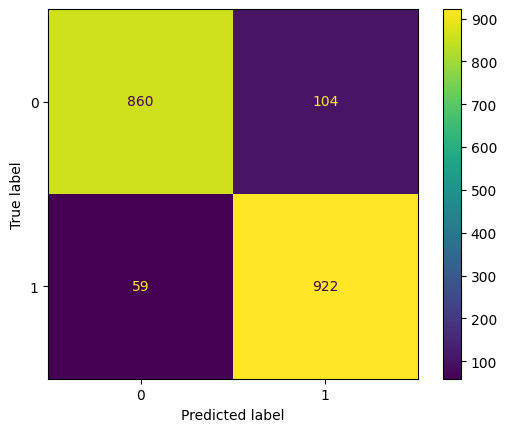

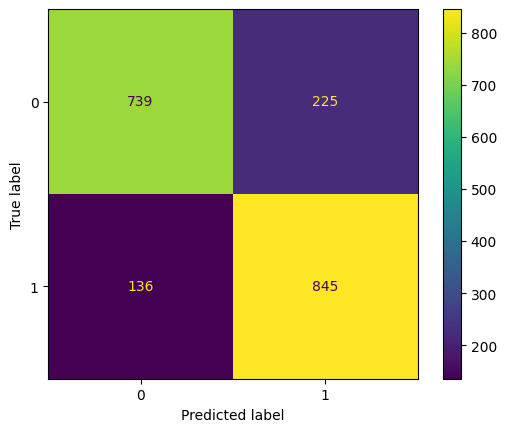

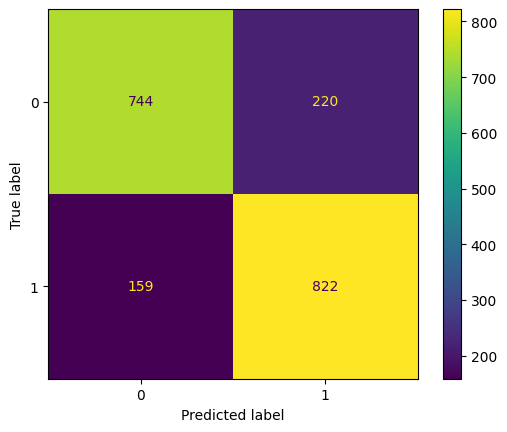

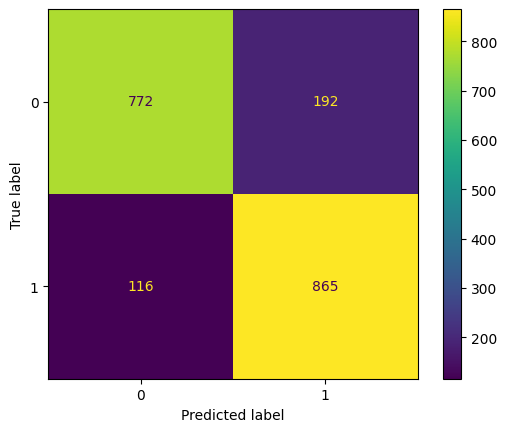

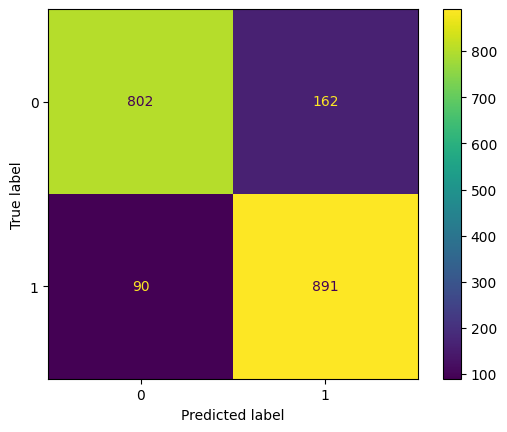

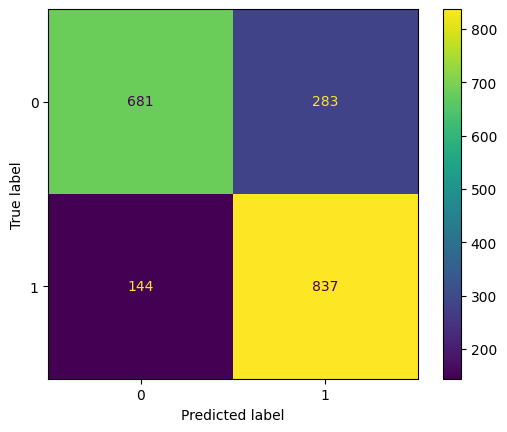

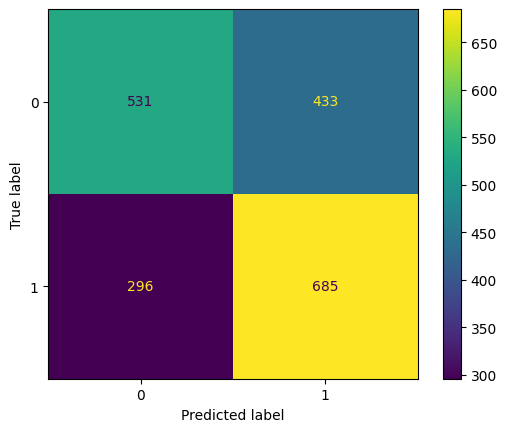

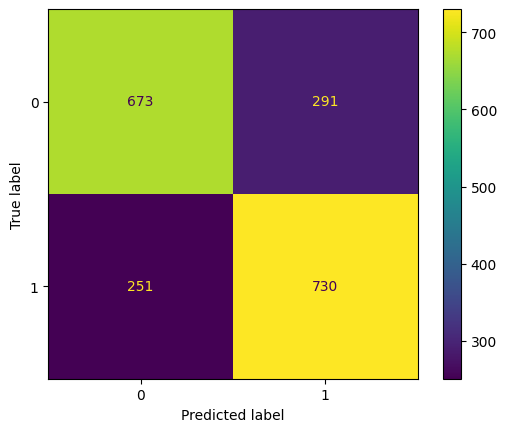

In [ ]:
model=[k, r, d, a, l, s, g, n, b, m]

for i in model:
    print('                 ', i)
    print('..................................................')
    i.fit(x_train, y_train)
    y_pred = i.predict(x_test)
    print('accuracy = ', accuracy_score(y_test, y_pred)*100)
    print(classification_report(y_test, y_pred))
    print(ConfusionMatrixDisplay.from_predictions(y_test, y_pred))
    print()
    print()

In [ ]:
from sklearn.model_selection import cross_val_score
import numpy as np

print("Cross Validation Scores for all models on training data:")
for i in model:
    print("                   ", i.__class__.__name__)
    print("***********************************************************")
    #using cv=3 and n_jobs=-1 for faster execution.
    scores = cross_val_score(i, x, y, cv=3, scoring='accuracy', n_jobs=-1)
    print(f"CV Accuracy Scores: {scores}")
    print(f"Mean Accuracy: {np.mean(scores)*100:.2f}%\n")


Cross Validation Scores for all models on training data:
                    KNeighborsClassifier
***********************************************************
CV Accuracy Scores: [0.84696081 0.86670781 0.88641975]
Mean Accuracy: 86.67%

                    RandomForestClassifier
***********************************************************
CV Accuracy Scores: [0.92193767 0.93921629 0.95061728]
Mean Accuracy: 93.73%

                    DecisionTreeClassifier
***********************************************************
CV Accuracy Scores: [0.87874113 0.90712743 0.91512346]
Mean Accuracy: 90.03%

                    AdaBoostClassifier
***********************************************************
CV Accuracy Scores: [0.79358223 0.81456341 0.83765432]
Mean Accuracy: 81.53%

                    LogisticRegression
***********************************************************
CV Accuracy Scores: [0.79080531 0.80839247 0.81604938]
Mean Accuracy: 80.51%

                    SVC
************************

In [ ]:
df

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,67.0,0,1,1,2,1,228.69,36.600000,1,1
1,0,61.0,0,0,1,3,0,202.21,28.893237,2,1
2,1,80.0,0,1,1,2,0,105.92,32.500000,2,1
3,0,49.0,0,0,1,2,1,171.23,34.400000,3,1
4,0,79.0,1,0,1,3,0,174.12,24.000000,2,1
...,...,...,...,...,...,...,...,...,...,...,...
5105,0,80.0,1,0,1,2,1,83.75,28.893237,2,0
5106,0,81.0,0,0,1,3,1,125.20,40.000000,2,0
5107,0,35.0,0,0,1,3,0,82.99,30.600000,2,0
5108,1,51.0,0,0,1,2,0,166.29,25.600000,1,0


In [ ]:
df.dtypes

gender                 int64
age                  float64
hypertension           int64
heart_disease          int64
ever_married           int64
work_type              int64
Residence_type         int64
avg_glucose_level    float64
bmi                  float64
smoking_status         int64
stroke                 int64
dtype: object

In [ ]:
gender=input("Enter gender:")
age=input("enter your age:")
hypertension=int(input("Enter hypertension"))
heart_disease=int(input("Enter heart disease"))
ever_married=input("Enter ever married")
work_type=input("Enter work type")
Residence_type=input("Enter Residence type")
avg_glucose_level=float(input("Enter avg glucose type"))
bmi = float(input("Enter bmi"))
smoking_status=input("Enter smoking status")



In [ ]:
#encode categorical columns
encoded_gender=le.transform([gender])[0]
encoded_married=le1.transform([ever_married])[0]
encoded_worktype=le2.transform([work_type])[0]
encoded_restype=le3.transform([Residence_type])[0]
encoded_smoking=le4.transform([smoking_status])[0]

#prediction
y2=r.predict(
    q.transform([[encoded_gender, age, hypertension, heart_disease, encoded_married, encoded_worktype, encoded_restype,
                  avg_glucose_level, bmi, encoded_smoking
                  ]])
)
y2

array([0])

In [ ]:
import pickle

In [ ]:
pickle.dump(r,open('stroke_model.save','wb'))
pickle.dump(q,open('stroke_scalar.save','wb'))
pickle.dump(le,open('encoded_gender.save','wb'))
pickle.dump(le1,open('encoded_married.save','wb'))
pickle.dump(le2,open('encoded_worktype.save','wb'))
pickle.dump(le3,open('encoded_restype.save','wb'))
pickle.dump(le4,open('encoded_smoking.save','wb'))
